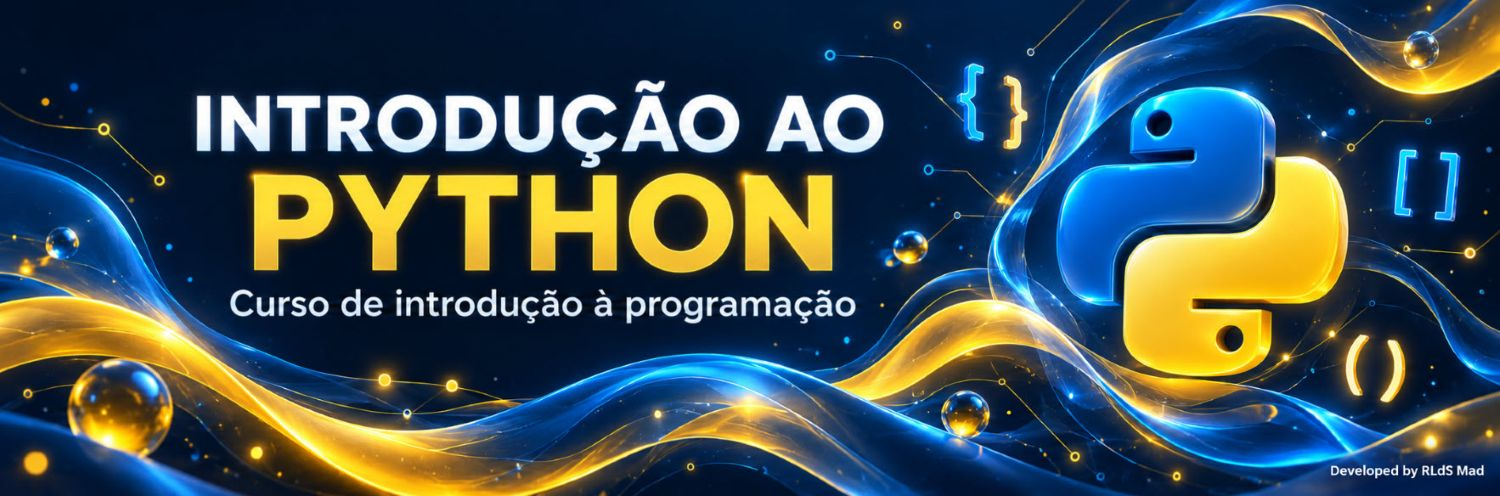

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_2_avancado/RLdS_N2_02_Pandas_Avancado.ipynb)


# Nível avançado · Módulo 2 – Pandas avançado
## Dados eficientes, validação e preparação para aprendizagem automática

Este é o terceiro módulo sobre **Pandas**. Aqui aprofundamos o armazenamento, a correção temporal, os contratos de dados e a composição de processos reproduzíveis.

**Pré-requisitos:** selecionar com `loc`, criar máscaras, converter tipos, usar `groupby`, `merge`, funções Python e ficheiros CSV. 

**Duração sugerida:** 10–14 horas com exercícios; o projeto autónomo exige tempo adicional.

**Objetivos:** ler Parquet com projeção e filtros; consultar SQLite com parâmetros; distinguir localização e conversão de fusos horários; validar contratos de dados; escrever transformações testáveis; usar janelas temporais sem informação futura; medir desempenho; preparar variáveis e avaliar um modelo sem fuga de informação.

Todos os dados são **sintéticos**, gerados com sementes fixas. O notebook é autónomo e não depende dos ficheiros dos anteriores. Depois de instalar as bibliotecas, todo o percurso funciona sem Internet.

**Nota:** algumas das bibliotecas Python apresentadas podem não ter sido lecionadas. Nesses casos, recorre ao respetivo módulo do curso ou, se não existir, à documentação oficial da biblioteca em questão.


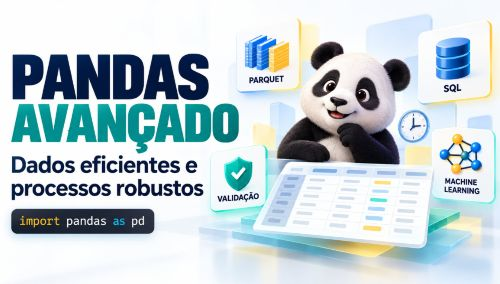


### Como executar
Executa de cima para baixo num kernel Python. As células criam ou substituem **apenas os ficheiros de demonstração** na pasta `pandas_avancado_lab`, dentro do diretório de trabalho. Guarda ficheiros teus noutro local. Reiniciar o kernel e executar tudo é a verificação final de reprodução. As saídas guardadas são uma execução de referência; tempos e métricas podem variar entre ambientes.

### Índice
1. Ambiente, cenário e contratos
2. Parquet, Arrow e partições
3. SQL parametrizado e agregação na origem
4. Fusos horários e horário de verão
5. Validação de esquemas e qualidade
6. Transformações com `pipe` e testes
7. Junções temporais, MultiIndex e janelas
8. Memória, vetorização e processamento por blocos
9. Preparação para aprendizagem automática
10. Projeto integrado e entrega auditável
11. Exercícios, soluções e projeto autónomo


## 1. Ambiente
Descomenta a instalação se alguma biblioteca estiver ausente. `%pip` utiliza o ambiente do kernel; reinicia-o depois da instalação. `sqlite3`, `unittest`, `timeit` e `zoneinfo` pertencem à biblioteca padrão do Python.

Usamos APIs disponíveis em Pandas 2.2+ e scikit-learn 1.2+. As versões realmente utilizadas ficam registadas. O backend Arrow é apresentado como opção, não como substituição automática de todos os tipos.


In [1]:
# O Colab já inclui estas bibliotecas. Noutros ambientes, descomenta a linha seguinte se faltar alguma.
# %pip install "pandas>=2.2" numpy pyarrow "scikit-learn>=1.2" matplotlib tzdata


In [2]:
from pathlib import Path
from io import StringIO
import json
import sqlite3
import platform
import hashlib
import timeit
import unittest
from importlib.metadata import version
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = Path.cwd() / "pandas_avancado_lab"
DADOS = RAIZ / "dados"
RESULTADOS = RAIZ / "resultados"
DADOS.mkdir(parents=True, exist_ok=True)
RESULTADOS.mkdir(parents=True, exist_ok=True)
VERSOES = {p: version(p) for p in ["pandas", "numpy", "pyarrow", "scikit-learn", "matplotlib"]}
VERSOES["python"] = platform.python_version()
display(pd.Series(VERSOES, name="versao"))
print("Diretório do laboratório:", RAIZ)


pandas           3.0.6
numpy            2.5.4
pyarrow         26.0.0
scikit-learn     1.9.1
matplotlib      3.11.2
python          3.12.3
Name: versao, dtype: str

Diretório do laboratório: /content/pandas_avancado_lab


### Cenário: operações de uma loja com entregas
Vamos usar dois conjuntos relacionados pelo contexto, sem juntar arbitrariamente as suas linhas:

- **Vendas:** uma linha por evento de venda, identificada por `evento_id`; instante UTC, região, canal, quantidade, preço unitário em cêntimos e desconto em pontos base.
- **Entregas:** uma linha por envio; queremos estimar a duração da entrega usando informação conhecida no momento da expedição.

O CRISP-DM continua a ser o enquadramento: compreender o problema e os dados, preparar, modelar, avaliar e disponibilizar. O processo é iterativo: uma regra que falha pode exigir nova investigação da origem.

**Convenções de negócio:** quantidade positiva; preço em cêntimos inteiros; desconto entre 0 e 5000 pontos base (0–50%); timestamps com fuso UTC; identificadores únicos e textuais. Não modelamos impostos nem devoluções. Estas regras pertencem ao exemplo, não são regras universais.


## 1.1 Gerar dados reproduzíveis

A amostra é suficientemente pequena para executar num computador comum, mas contém diversidade de tipos e períodos. Os valores monetários são inteiros para evitar a representação binária dos decimais nos cálculos de cêntimos.


In [3]:
rng = np.random.default_rng(2026)
n = 960
vendas = pd.DataFrame({
    "evento_id": pd.Series([f"E{i:06d}" for i in range(n)], dtype="string"),
    "instante_utc": pd.date_range("2025-01-01", periods=n, freq="3h", tz="UTC"),
    "regiao": pd.Series(rng.choice(["Norte", "Centro", "Sul"], n), dtype="string"),
    "canal": pd.Series(rng.choice(["online", "loja"], n), dtype="string"),
    "quantidade": pd.Series(rng.integers(1, 9, n), dtype="Int64"),
    "preco_centimos": pd.Series(rng.integers(100, 10000, n), dtype="Int64"),
    "desconto_pb": pd.Series(rng.choice([0, 500, 1000], n), dtype="Int64")
})
vendas.to_parquet(DADOS / "vendas_origem.parquet", engine="pyarrow", index=False)
vendas.to_csv(DADOS / "vendas_origem.csv", index=False)
display(vendas.head())
print("Cobertura:", vendas["instante_utc"].min(), "a", vendas["instante_utc"].max())


,evento_id,instante_utc,regiao,canal,quantidade,preco_centimos,desconto_pb
0,E000000,2025-01-01 00:00:00+00:00,Sul,online,1,3733,500
1,E000001,2025-01-01 03:00:00+00:00,Norte,online,7,537,1000
2,E000002,2025-01-01 06:00:00+00:00,Norte,online,8,4651,0
3,E000003,2025-01-01 09:00:00+00:00,Centro,online,4,1178,500
4,E000004,2025-01-01 12:00:00+00:00,Centro,online,8,4431,500


Cobertura: 2025-01-01 00:00:00+00:00 a 2025-04-30 21:00:00+00:00


### Dicionário e unidades
| Coluna | Tipo pretendido | Regra |
|---|---|---|
| evento_id | string | Não nulo, único, padrão E seguido de 6 algarismos |
| instante_utc | datetime com fuso UTC | Não nulo |
| regiao | string | Norte, Centro ou Sul |
| canal | string | online ou loja |
| quantidade | inteiro anulável | 1 a 100 |
| preco_centimos | inteiro anulável | 1 a 1 000 000 cêntimos |
| desconto_pb | inteiro anulável | 0 a 5000 pontos base |

**Nota:** 100 pontos base correspondem a 1%; 1000 pontos base correspondem a 10%. A representação em inteiros exige conhecer a unidade e escolher uma regra de arredondamento.


## 2. CSV versus Parquet

**Parquet** é um `formato binário por colunas`. Permite ler apenas as colunas necessárias e, em condições adequadas, evitar grupos de linhas ou partições que não correspondem aos filtros. A eficiência depende do volume, da distribuição dos dados, da compressão e do motor.


In [4]:
original = pd.read_parquet(DADOS / "vendas_origem.parquet", engine="pyarrow")
pd.testing.assert_frame_equal(original, vendas)
comparacao_ficheiros = pd.DataFrame({
    "ficheiro": ["vendas_origem.csv", "vendas_origem.parquet"],
    "bytes": [(DADOS / "vendas_origem.csv").stat().st_size,
              (DADOS / "vendas_origem.parquet").stat().st_size]
})
display(comparacao_ficheiros)
display(original.dtypes)
print("Tipos e valores preservados neste round-trip.")


,ficheiro,bytes
0,vendas_origem.csv,54043
1,vendas_origem.parquet,23675


evento_id                      string
instante_utc      datetime64[us, UTC]
regiao                         string
canal                          string
quantidade                      Int64
preco_centimos                  Int64
desconto_pb                     Int64
dtype: object

Tipos e valores preservados neste round-trip.


**Interpretação:** o CSV não traz um esquema de tipos equivalente ao Parquet. O resultado de tamanho nesta amostra não demonstra que um formato seja sempre mais pequeno ou rápido.


## 2.1 Projeção de colunas e filtros

`columns` limita as colunas devolvidas. Os filtros são uma lista de condições ligadas por E; uma lista de listas permite alternativas ligadas por OU. Com `engine="pyarrow"`, os predicados podem ser aplicados durante a leitura.


In [5]:
recorte = pd.read_parquet(
    DADOS / "vendas_origem.parquet", engine="pyarrow",
    columns=["evento_id", "regiao", "quantidade"],
    filters=[("regiao", "==", "Norte"), ("quantidade", ">=", 5)]
)
esperado = vendas.loc[(vendas["regiao"] == "Norte") & (vendas["quantidade"] >= 5),
                       ["evento_id", "regiao", "quantidade"]].reset_index(drop=True)
pd.testing.assert_frame_equal(recorte.reset_index(drop=True), esperado)
display(recorte.head())
print("Linhas selecionadas:", len(recorte))


,evento_id,regiao,quantidade
0,E000001,Norte,7
1,E000002,Norte,8
2,E000006,Norte,7
3,E000024,Norte,8
4,E000036,Norte,8


Linhas selecionadas: 172


**Atenção:** obter menos linhas não prova que o motor leu menos bytes. Num ficheiro pouco organizado, pode ser necessário ler vários grupos de linhas antes de aplicar o filtro.


## 2.2 Tipos Arrow no Pandas

`dtype_backend="pyarrow"` devolve colunas apoiadas em tipos Arrow. Operações, consumo de memória e integração com outras bibliotecas podem diferir dos tipos NumPy e dos tipos anuláveis de Pandas.


In [6]:
arrow_df = pd.read_parquet(DADOS / "vendas_origem.parquet", dtype_backend="pyarrow")
display(arrow_df.dtypes)
print("Memória Pandas (bytes):", vendas.memory_usage(deep=True).sum())
print("Memória Arrow (bytes):", arrow_df.memory_usage(deep=True).sum())
assert arrow_df["quantidade"].sum() == vendas["quantidade"].sum()
# Se uma biblioteca exigir arrays NumPy, converte explicitamente a coluna pretendida.
quantidades_numpy = arrow_df["quantidade"].to_numpy(dtype="int64")
print(quantidades_numpy[:5])


evento_id                  large_string[pyarrow]
instante_utc      timestamp[us, tz=UTC][pyarrow]
regiao                     large_string[pyarrow]
canal                      large_string[pyarrow]
quantidade                        int64[pyarrow]
preco_centimos                    int64[pyarrow]
desconto_pb                       int64[pyarrow]
dtype: object

Memória Pandas (bytes): 72762
Memória Arrow (bytes): 70362
[1 7 8 4 8]


## 2.3 Dataset particionado

Particionar por mês pode facilitar leituras que selecionam períodos. Evita particionar por uma chave quase única: produziria muitos ficheiros pequenos. Este exemplo usa nomes determinísticos e substitui as partições geradas correspondentes em cada execução.


In [7]:
particionadas = vendas.assign(mes=vendas["instante_utc"].dt.strftime("%Y-%m"))
esquema_particao = pa.schema([("mes", pa.string())])
ds.write_dataset(
    pa.Table.from_pandas(particionadas, preserve_index=False),
    base_dir=str(DADOS / "vendas_por_mes"), format="parquet",
    partitioning=ds.partitioning(esquema_particao, flavor="hive"),
    basename_template="parte-{i}.parquet", existing_data_behavior="delete_matching"
)
fevereiro = pd.read_parquet(DADOS / "vendas_por_mes", engine="pyarrow",
                             filters=[("mes", "==", "2025-02")])
assert len(fevereiro) == (particionadas["mes"] == "2025-02").sum()
display(fevereiro.head())
print("Partições:", sorted(p.name for p in (DADOS / "vendas_por_mes").iterdir()))


,evento_id,instante_utc,regiao,canal,quantidade,preco_centimos,desconto_pb,mes
0,E000248,2025-02-01 00:00:00+00:00,Sul,online,2,8378,500,2025-02
1,E000249,2025-02-01 03:00:00+00:00,Norte,loja,1,1870,500,2025-02
2,E000250,2025-02-01 06:00:00+00:00,Norte,online,6,6650,0,2025-02
3,E000251,2025-02-01 09:00:00+00:00,Norte,loja,5,6360,500,2025-02
4,E000252,2025-02-01 12:00:00+00:00,Centro,online,6,527,500,2025-02


Partições: ['mes=2025-01', 'mes=2025-02', 'mes=2025-03', 'mes=2025-04']


**Reprodução:** `delete_matching` substitui os diretórios de partição presentes no lote atual. Não é uma estratégia geral de atualização incremental: partições antigas ausentes do lote atual não são eliminadas. O conjunto sintético deste notebook é sempre o mesmo.


### Exercício 1

Lê apenas `evento_id` e `preco_centimos` do Parquet, selecionando o canal online e preços de pelo menos 5000 cêntimos. Confirma o resultado com um filtro em memória.

Tenta antes de consultar a solução no final.


In [8]:
# Exercício 1 - escreve a tua resolução aqui.


## 3. Criar uma base SQLite de laboratório

SQLite permite praticar sem servidor. Na base dedicada ao laboratório, `to_sql(..., if_exists="replace")` substitui a tabela de treino. Guardamos timestamps como texto ISO uniforme em UTC; a leitura volta a convertê-los explicitamente.


In [9]:
caminho_db = DADOS / "loja_treino.sqlite"
sql_origem = vendas.copy()
sql_origem["instante_utc"] = sql_origem["instante_utc"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
from contextlib import closing  # closing() garante que a ligação à base de dados é fechada
with closing(sqlite3.connect(caminho_db)) as con, con:
    sql_origem.to_sql("vendas", con, index=False, if_exists="replace")
    con.execute("CREATE INDEX IF NOT EXISTS idx_vendas_regiao_data ON vendas(regiao, instante_utc)")
    total_db = con.execute("SELECT COUNT(*) FROM vendas").fetchone()[0]
assert total_db == len(vendas)
print("Linhas na tabela:", total_db)


Linhas na tabela: 960


## 3.1 Consultas parametrizadas

Os valores vão em `params`, separados do texto SQL. No SQLite o marcador é `?`; outros motores podem usar outra sintaxe. Parâmetros não substituem nomes de tabelas ou colunas: esses identificadores devem ser fixos ou escolhidos numa lista controlada.


In [10]:
consulta = """
SELECT evento_id, instante_utc, regiao, quantidade, preco_centimos
FROM vendas
WHERE regiao = ? AND instante_utc >= ?
ORDER BY instante_utc
"""
with closing(sqlite3.connect(caminho_db)) as con:
    do_sql = pd.read_sql_query(consulta, con, params=("Norte", "2025-03-01T00:00:00Z"))
do_sql["instante_utc"] = pd.to_datetime(do_sql["instante_utc"], utc=True)
display(do_sql.head())
# A entrada é tratada como um valor literal, não como instrução SQL.
with closing(sqlite3.connect(caminho_db)) as con:
    literal = pd.read_sql_query("SELECT COUNT(*) AS n FROM vendas WHERE regiao = ?", con,
                                params=("Norte' OR 1=1 --",))
assert literal.loc[0, "n"] == 0
print("Valor literal não alterou a consulta.")


,evento_id,instante_utc,regiao,quantidade,preco_centimos
0,E000473,2025-03-01 03:00:00+00:00,Norte,4,2713
1,E000482,2025-03-02 06:00:00+00:00,Norte,3,7854
2,E000486,2025-03-02 18:00:00+00:00,Norte,8,3754
3,E000489,2025-03-03 03:00:00+00:00,Norte,2,2453
4,E000491,2025-03-03 09:00:00+00:00,Norte,6,5404


Valor literal não alterou a consulta.


## 3.2 Agregar na origem e conferir com Pandas

Se só precisas de um resumo, agrega na base de dados para reduzir a transferência. Definições de tipos, ausências e arredondamentos podem variar entre SQL e Pandas: compara os resultados.


In [11]:
with closing(sqlite3.connect(caminho_db)) as con:
    resumo_sql = pd.read_sql_query("""
        SELECT regiao, COUNT(*) AS linhas, SUM(quantidade) AS unidades,
               SUM(quantidade * preco_centimos) AS bruto_centimos
        FROM vendas GROUP BY regiao ORDER BY regiao
    """, con)
resumo_pd = (vendas.assign(bruto_centimos=vendas["quantidade"] * vendas["preco_centimos"])
             .groupby("regiao", as_index=False)
             .agg(linhas=("evento_id", "size"), unidades=("quantidade", "sum"),
                  bruto_centimos=("bruto_centimos", "sum")))
np.testing.assert_array_equal(resumo_sql[["linhas", "unidades", "bruto_centimos"]].to_numpy(),
                              resumo_pd[["linhas", "unidades", "bruto_centimos"]].to_numpy())
assert resumo_sql["regiao"].tolist() == resumo_pd["regiao"].tolist()
display(resumo_sql)


,regiao,linhas,unidades,bruto_centimos
0,Centro,334,1496,7716280
1,Norte,322,1485,7193412
2,Sul,304,1418,7070981


### Exercício 2

Escreve uma consulta parametrizada que devolva o total de unidades do canal loja, com preços inferiores a 2000 cêntimos. Confirma com Pandas. Usa `COALESCE` para que uma seleção vazia devolva zero.

Tenta antes de consultar a solução no final.


In [12]:
# Exercício 2 - escreve a tua resolução aqui.


## 4. UTC, localização e conversão de fusos

`tz_localize` atribui um fuso a horas sem fuso, interpretando-as como horas locais. `tz_convert` converte instantes já localizados, preservando o instante real. Não são operações intercambiáveis.


In [13]:
horas_sem_fuso = pd.Series(pd.to_datetime(["2025-01-15 12:00", "2025-07-15 12:00"]))
horas_lisboa = horas_sem_fuso.dt.tz_localize("Europe/Lisbon")
horas_utc = horas_lisboa.dt.tz_convert("UTC")
display(pd.DataFrame({"hora_local_sem_fuso": horas_sem_fuso,
                      "Lisboa": horas_lisboa, "UTC": horas_utc}))
vendas_local = vendas.assign(instante_lisboa=vendas["instante_utc"].dt.tz_convert("Europe/Lisbon"))
assert vendas_local["instante_lisboa"].dt.tz_convert("UTC").equals(vendas["instante_utc"])


,hora_local_sem_fuso,Lisboa,UTC
0,2025-01-15 12:00:00,2025-01-15 12:00:00+00:00,2025-01-15 12:00:00+00:00
1,2025-07-15 12:00:00,2025-07-15 12:00:00+01:00,2025-07-15 11:00:00+00:00


**Interpretação:** ao meio-dia de julho em Lisboa corresponde 11h UTC, enquanto em janeiro corresponde 12h UTC. O fuso contém regras históricas de mudança de hora; um deslocamento fixo de +1h não as substitui.


## 4.1 Horas inexistentes e ambíguas

Na entrada do horário de verão pode haver horas locais que não existiram; na saída, horas repetidas. É preciso escolher uma política explícita. Para dados reais, investiga a origem antes de deslocar ou descartar horas.


In [14]:
primavera = pd.Series(pd.to_datetime(["2025-03-30 00:30", "2025-03-30 01:30", "2025-03-30 02:30"]))
primavera_segura = primavera.dt.tz_localize("Europe/Lisbon", nonexistent="NaT")
display(pd.DataFrame({"original": primavera, "localizado": primavera_segura}))
assert primavera_segura.isna().sum() == 1

outono = pd.Series(pd.to_datetime(["2025-10-26 01:30", "2025-10-26 01:30"]))
# Informação adicional da origem indica a primeira e a segunda ocorrência.
outono_local = outono.dt.tz_localize("Europe/Lisbon", ambiguous=[True, False])
display(pd.DataFrame({"Lisboa": outono_local, "UTC": outono_local.dt.tz_convert("UTC")}))
assert outono_local.dt.tz_convert("UTC").nunique() == 2


,original,localizado
0,2025-03-30 00:30:00,2025-03-30 00:30:00+00:00
1,2025-03-30 01:30:00,NaT
2,2025-03-30 02:30:00,2025-03-30 02:30:00+01:00


,Lisboa,UTC
0,2025-10-26 01:30:00+01:00,2025-10-26 00:30:00+00:00
1,2025-10-26 01:30:00+00:00,2025-10-26 01:30:00+00:00


`ambiguous=True` seleciona a ocorrência no horário de verão; `False` seleciona a ocorrência no horário padrão. Se a origem não permitir distinguir as ocorrências, `ambiguous="NaT"` permite sinalizar o problema em vez de adivinhar.


## 4.2 Agregar pelo dia local

A definição de “dia” depende do contexto. Converter para a hora local antes de agrupar pode mudar a distribuição diária. Evitamos retirar o fuso antes de identificar os períodos locais.


In [15]:
diario = (vendas_local.set_index("instante_lisboa")["quantidade"]
          .resample("D").sum().rename("unidades"))
display(diario.head())
# Dois instantes consecutivos em UTC podem cair no mesmo horário local repetido.
instantes_outono = pd.Series(pd.to_datetime(["2025-10-26T00:30Z", "2025-10-26T01:30Z"], utc=True))
display(instantes_outono.dt.tz_convert("Europe/Lisbon"))
assert diario.sum() == vendas["quantidade"].sum()


instante_lisboa
2025-01-01 00:00:00+00:00    37
2025-01-02 00:00:00+00:00    42
2025-01-03 00:00:00+00:00    40
2025-01-04 00:00:00+00:00    37
2025-01-05 00:00:00+00:00    41
Freq: D, Name: unidades, dtype: Int64

0   2025-10-26 01:30:00+01:00
1   2025-10-26 01:30:00+00:00
dtype: datetime64[us, Europe/Lisbon]

### Exercício 3

Converte `2025-07-01 23:30 UTC` para Europe/Lisbon. Mostra que o dia local já é 2 de julho. Explica por que remover o fuso antes de converter pode dar uma interpretação errada.

Tenta antes de consultar a solução no final.


In [16]:
# Exercício 3 - escreve a tua resolução aqui.


## 5. Contratos de dados: estrutura, tipos e domínio
Um **esquema** descreve colunas e tipos; um **contrato** pode também impor unicidade, limites, categorias permitidas e relações entre valores. Validar é diferente de limpar: uma validação deteta uma violação, mas não a corrige nem apaga dados.

Vamos escrever um validador sem uma biblioteca adicional. Em projetos maiores, bibliotecas de validação de esquemas podem ajudar, mas as regras continuam a precisar de uma justificação de negócio. O validador seguinte exige as colunas exatas e não nulas; colunas calculadas só são adicionadas depois da validação de entrada.


In [17]:
COLUNAS = ["evento_id", "instante_utc", "regiao", "canal", "quantidade", "preco_centimos", "desconto_pb"]

def validar_vendas(df):
    erros = []
    if set(df.columns) != set(COLUNAS):
        faltam = sorted(set(COLUNAS) - set(df.columns))
        extras = sorted(set(df.columns) - set(COLUNAS))
        raise ValueError(f"Colunas inválidas; faltam={faltam}; extras={extras}")
    for coluna in COLUNAS:
        if df[coluna].isna().any():
            erros.append(f"{coluna}: valores ausentes")
    if not pd.api.types.is_string_dtype(df["evento_id"].dtype):
        erros.append("evento_id: tipo de texto esperado")
    if not df["evento_id"].astype("string").str.fullmatch(r"E\d{6}", na=False).all():
        erros.append("evento_id: formato inválido")
    if df["evento_id"].duplicated().any():
        erros.append("evento_id: duplicado")
    dtype_tempo = df["instante_utc"].dtype
    if not isinstance(dtype_tempo, pd.DatetimeTZDtype) or str(dtype_tempo.tz) != "UTC":
        erros.append("instante_utc: datetime com fuso UTC esperado")
    for coluna, valores in {"regiao": ["Norte", "Centro", "Sul"], "canal": ["online", "loja"]}.items():
        if not df[coluna].isin(valores).all():
            erros.append(f"{coluna}: categoria inválida")
    limites = {"quantidade": (1, 100), "preco_centimos": (1, 1_000_000), "desconto_pb": (0, 5000)}
    for coluna, (minimo, maximo) in limites.items():
        if not pd.api.types.is_integer_dtype(df[coluna].dtype):
            erros.append(f"{coluna}: inteiro esperado")
        else:
            if not df[coluna].between(minimo, maximo).fillna(False).all():
                erros.append(f"{coluna}: fora do domínio")
    if erros:
        raise ValueError("; ".join(erros))
    return df

validar_vendas(vendas)
print("Contrato de entrada cumprido.")


Contrato de entrada cumprido.


## 5.1 Introduzir erros e observar falhas úteis

O teste de uma validação deve incluir dados inválidos. Não basta verificar que o conjunto habitual passa.


In [18]:
avariadas = vendas.head(4).copy()
avariadas.loc[1, "quantidade"] = 0
avariadas.loc[2, "evento_id"] = avariadas.loc[0, "evento_id"]
avariadas.loc[3, "regiao"] = "Desconhecida"
try:
    validar_vendas(avariadas)
except ValueError as erro:
    print("Falha esperada:", erro)
else:
    raise AssertionError("O validador deveria rejeitar esta entrada.")
# Falha estrutural é tratada antes das regras de conteúdo.
try:
    validar_vendas(vendas.drop(columns="canal"))
except ValueError as erro:
    print("Falha estrutural esperada:", erro)


Falha esperada: evento_id: duplicado; regiao: categoria inválida; quantidade: fora do domínio
Falha estrutural esperada: Colunas inválidas; faltam=['canal']; extras=[]


### Exercício 4

Cria uma cópia com um preço negativo e outra com timestamps sem fuso. Confirma que o validador rejeita ambas. Não alteres `vendas`.

Tenta antes de consultar a solução no final.


In [19]:
# Exercício 4 - escreve a tua resolução aqui.


## 6. Funções pequenas e composição com pipe

Cada função recebe uma tabela, devolve outra e não modifica a entrada. A função de cálculo é idempotente: executá-la novamente não aplica o desconto duas vezes. Definimos arredondamento ao cêntimo, por linha, com metade para cima para valores não negativos.


In [20]:
def calcular_montantes(df):
    # O validador assegura limites muito inferiores à capacidade do int64.
    bruto = df["quantidade"] * df["preco_centimos"]
    numerador = bruto * (10000 - df["desconto_pb"])
    liquido = (numerador + 5000) // 10000
    return df.assign(bruto_centimos=bruto, liquido_centimos=liquido)

def acrescentar_periodo(df):
    local = df["instante_utc"].dt.tz_convert("Europe/Lisbon")
    return df.assign(mes_local=local.dt.strftime("%Y-%m"))

antes = vendas.copy(deep=True)
preparadas = (vendas.pipe(validar_vendas)
              .pipe(calcular_montantes)
              .pipe(acrescentar_periodo))
pd.testing.assert_frame_equal(vendas, antes)
pd.testing.assert_frame_equal(calcular_montantes(preparadas), preparadas)
display(preparadas.head())


,evento_id,instante_utc,regiao,canal,quantidade,preco_centimos,desconto_pb,bruto_centimos,liquido_centimos,mes_local
0,E000000,2025-01-01 00:00:00+00:00,Sul,online,1,3733,500,3733,3546,2025-01
1,E000001,2025-01-01 03:00:00+00:00,Norte,online,7,537,1000,3759,3383,2025-01
2,E000002,2025-01-01 06:00:00+00:00,Norte,online,8,4651,0,37208,37208,2025-01
3,E000003,2025-01-01 09:00:00+00:00,Centro,online,4,1178,500,4712,4476,2025-01
4,E000004,2025-01-01 12:00:00+00:00,Centro,online,8,4431,500,35448,33676,2025-01


**Arredondamento:** o total de linhas arredondadas pode diferir de arredondar uma única vez o total não arredondado. A regra deve ser acordada. Esta fórmula não serve diretamente para devoluções negativas.


## 6.1 Testes de comportamento e invariantes

`assert_frame_equal` compara valores, ordem e tipos. Os testes incluem um exemplo de fronteira de arredondamento, ausência de mutação, repetição do cálculo e rejeição de entradas incorretas. As exceções esperadas são capturadas pelo teste.


In [21]:
class TestarVendas(unittest.TestCase):
    def test_arredondamento_metade_para_cima(self):
        amostra = vendas.head(1).copy()
        amostra["quantidade"] = pd.Series([1], dtype="Int64")
        amostra["preco_centimos"] = pd.Series([101], dtype="Int64")
        amostra["desconto_pb"] = pd.Series([5000], dtype="Int64")
        resultado = calcular_montantes(validar_vendas(amostra))
        self.assertEqual(resultado.loc[0, "liquido_centimos"], 51)

    def test_sem_mutacao_e_idempotencia(self):
        entrada = vendas.head(6).copy()
        copia = entrada.copy(deep=True)
        saida = calcular_montantes(entrada)
        pd.testing.assert_frame_equal(entrada, copia)
        pd.testing.assert_frame_equal(calcular_montantes(saida), saida)

    def test_falha_quantidade(self):
        entrada = vendas.head(2).copy()
        entrada.loc[0, "quantidade"] = -1
        with self.assertRaisesRegex(ValueError, "quantidade"):
            validar_vendas(entrada)

    def test_falha_duplicado(self):
        entrada = pd.concat([vendas.head(1), vendas.head(1)], ignore_index=True)
        with self.assertRaisesRegex(ValueError, "duplicado"):
            validar_vendas(entrada)

    def test_falha_coluna(self):
        with self.assertRaisesRegex(ValueError, "Colunas"):
            validar_vendas(vendas.drop(columns="regiao"))

    def test_invariantes(self):
        saida = calcular_montantes(validar_vendas(vendas))
        self.assertTrue(saida["liquido_centimos"].le(saida["bruto_centimos"]).all())
        self.assertTrue(saida["liquido_centimos"].ge(0).all())
        self.assertEqual(len(saida), len(vendas))

suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestarVendas)
execucao_testes = unittest.TextTestRunner(stream=__import__("sys").stdout, verbosity=2).run(suite)
assert execucao_testes.wasSuccessful()


test_arredondamento_metade_para_cima (__main__.TestarVendas.test_arredondamento_metade_para_cima) ... 

ok


test_falha_coluna (__main__.TestarVendas.test_falha_coluna) ... 

ok


test_falha_duplicado (__main__.TestarVendas.test_falha_duplicado) ... 

...

test_invariantes (__main__.TestarVendas.test_invariantes) ... 

ok


test_sem_mutacao_e_idempotencia (__main__.TestarVendas.test_sem_mutacao_e_idempotencia) ... 

ok


----------------------------------------------------------------------
Ran 6 tests in 0.040s

OK


### Copy-on-Write e alterações seguras
**Pandas 3 usa Copy-on-Write** como comportamento padrão. Escreve atualizações explícitas com `loc` e não dependas de uma seleção modificar a tabela original. O padrão abaixo funciona também no percurso com Pandas 2.2, pois a cópia é intencional.


In [22]:
copia = vendas.loc[vendas["canal"] == "online"].copy()
copia.loc[:, "desconto_pb"] = 0
assert vendas.equals(antes)
print("A modificação da cópia não alterou a origem.")


A modificação da cópia não alterou a origem.


### Exercício 5

Escreve um teste que rejeite `desconto_pb=5001` e outro que confirme que desconto zero mantém o montante bruto. Executa os testes sem provocar um erro não capturado no notebook.

Tenta antes de consultar a solução no final.


In [23]:
# Exercício 5 - escreve a tua resolução aqui.


## 7. Junção temporal com merge_asof

Uma junção de igualdade não resolve “usar a taxa conhecida mais recente”. `merge_asof` pode procurar a última observação anterior. Os dois lados têm de estar ordenados pela chave temporal. `direction="backward"` evita procurar uma taxa futura; `tolerance` limita a antiguidade permitida.


In [24]:
taxas = pd.DataFrame({
    "instante_utc": pd.to_datetime(["2025-01-01T00:00Z", "2025-02-01T00:00Z", "2025-03-01T00:00Z"], utc=True),
    "fator_exemplo": [1.0, 1.05, 1.02]
})
taxas = taxas.rename(columns={"instante_utc": "instante_taxa"})
com_taxa = pd.merge_asof(
    preparadas.sort_values("instante_utc"), taxas.sort_values("instante_taxa"),
    left_on="instante_utc", right_on="instante_taxa", direction="backward",
    tolerance=pd.Timedelta("35D")
)
conhecidas = com_taxa["instante_taxa"].notna()
assert (com_taxa.loc[conhecidas, "instante_taxa"] <= com_taxa.loc[conhecidas, "instante_utc"]).all()
assert len(com_taxa) == len(preparadas)
display(com_taxa[["instante_utc", "instante_taxa", "fator_exemplo"]].tail())
print("Linhas sem taxa suficientemente recente:", (~conhecidas).sum())


,instante_utc,instante_taxa,fator_exemplo
955,2025-04-30 09:00:00+00:00,NaT,NaN
956,2025-04-30 12:00:00+00:00,NaT,NaN
957,2025-04-30 15:00:00+00:00,NaT,NaN
958,2025-04-30 18:00:00+00:00,NaT,NaN
959,2025-04-30 21:00:00+00:00,NaT,NaN


Linhas sem taxa suficientemente recente: 207


As ausências no fim são esperadas: não há nova taxa depois de março e a tolerância expira. Não usamos `bfill`, pois poderia trazer informação futura. Os fatores são fictícios, não são taxas de câmbio reais.


## 7.1 MultiIndex, unstack e stack

Um MultiIndex representa vários níveis de etiquetas. Pode ser útil em resumos por região e mês. Nem sempre é necessário: uma tabela com colunas normais também pode ser mais conveniente.


In [25]:
por_regiao_mes = preparadas.groupby(["regiao", "mes_local"])["liquido_centimos"].sum()
display(por_regiao_mes.head(8))
matriz = por_regiao_mes.unstack("mes_local")
display(matriz)
reconstituido = matriz.stack().rename("liquido_centimos")
# Nestes dados todas as combinações existem; não perdemos células ausentes.
assert reconstituido.sort_index().equals(por_regiao_mes.sort_index())
display(por_regiao_mes.xs("Norte", level="regiao"))


regiao  mes_local
Centro  2025-01      1958649
        2025-02      1880448
        2025-03      2016323
        2025-04      1461687
Norte   2025-01      1506477
        2025-02      1714334
        2025-03      1750174
        2025-04      1880389
Name: liquido_centimos, dtype: Int64

mes_local,2025-01,2025-02,2025-03,2025-04
regiao,,,,
Centro,1958649,1880448,2016323,1461687
Norte,1506477,1714334,1750174,1880389
Sul,1644957,1616476,1834361,1618320


mes_local
2025-01    1506477
2025-02    1714334
2025-03    1750174
2025-04    1880389
Name: liquido_centimos, dtype: Int64

## 7.2 Janelas históricas por grupo

Uma média móvel de três observações não é uma média dos últimos três dias. Para variáveis preditivas, excluímos a observação atual: a sua quantidade ainda não estaria disponível antes do evento. A ordenação temporal precede qualquer janela.


In [26]:
historico = preparadas.sort_values("instante_utc").copy()
historico["media_3_eventos_anteriores"] = (historico.groupby("regiao")["quantidade"]
    .transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean()))
primeiros = historico.groupby("regiao").head(1)
assert primeiros["media_3_eventos_anteriores"].isna().all()
display(historico[["instante_utc", "regiao", "quantidade", "media_3_eventos_anteriores"]].head(10))

norte = historico.loc[historico["regiao"] == "Norte"].set_index("instante_utc")
janela_tempo = norte["quantidade"].rolling("7D", closed="left", min_periods=1).mean()
display(janela_tempo.head())


,instante_utc,regiao,quantidade,media_3_eventos_anteriores
0,2025-01-01 00:00:00+00:00,Sul,1,NaN
1,2025-01-01 03:00:00+00:00,Norte,7,NaN
2,2025-01-01 06:00:00+00:00,Norte,8,7.000000
3,2025-01-01 09:00:00+00:00,Centro,4,NaN
4,2025-01-01 12:00:00+00:00,Centro,8,4.000000
5,2025-01-01 15:00:00+00:00,Centro,1,6.000000
6,2025-01-01 18:00:00+00:00,Norte,7,7.500000
7,2025-01-01 21:00:00+00:00,Centro,1,4.333333
8,2025-01-02 00:00:00+00:00,Centro,6,3.333333
9,2025-01-02 03:00:00+00:00,Centro,8,2.666667


instante_utc
2025-01-01 03:00:00+00:00         NaN
2025-01-01 06:00:00+00:00    7.000000
2025-01-01 18:00:00+00:00    7.500000
2025-01-02 21:00:00+00:00    7.333333
2025-01-03 06:00:00+00:00    6.000000
Name: quantidade, dtype: float64

`closed="left"` usa [t − 7 dias, t), excluindo o evento em t. Aqui os instantes são únicos. Com eventos simultâneos, define também a ordem e o momento de disponibilidade dos dados. Excluir o presente evita uma fonte de fuga, mas não substitui a avaliação da disponibilidade real de cada variável.


### Exercício 6

Para a região Sul, calcula a soma das quantidades dos sete dias anteriores, excluindo o evento atual. Confirma que a primeira linha não tem histórico e que o valor da segunda coincide com a primeira quantidade, se estiver dentro dos sete dias.

Tenta antes de consultar a solução no final.


In [27]:
# Exercício 6 - escreve a tua resolução aqui.


## 8. Memória: medir antes de otimizar

Categorias repetidas podem beneficiar de `category`; tipos inteiros menores exigem verificar limites. Nem todas as colunas beneficiam de todas as conversões. `memory_usage(deep=True)` estima a memória das colunas, não o pico de memória de todo o processo.


In [28]:
otimizadas = vendas.copy()
otimizadas["regiao"] = otimizadas["regiao"].astype("category")
otimizadas["canal"] = otimizadas["canal"].astype("category")
otimizadas["quantidade"] = pd.to_numeric(otimizadas["quantidade"], downcast="integer")
memoria = pd.DataFrame({"antes_bytes": vendas.memory_usage(deep=True),
                        "depois_bytes": otimizadas.memory_usage(deep=True)})
display(memoria)
print("Poupança estimada:", int(memoria["antes_bytes"].sum() - memoria["depois_bytes"].sum()), "bytes")
assert otimizadas["quantidade"].sum() == vendas["quantidade"].sum()


,antes_bytes,depois_bytes
Index,132,132
evento_id,14400,14400
instante_utc,7680,7680
regiao,12206,999
canal,12424,987
quantidade,8640,1920
preco_centimos,8640,8640
desconto_pb,8640,8640


Poupança estimada: 29364 bytes


## 8.1 Vetorização versus apply: medição reproduzível

Comparamos duas implementações da mesma fórmula e confirmamos primeiro a igualdade. Medimos a mediana de três repetições de uma execução, no mesmo conjunto. O resultado é local e não permite concluir sobre todos os cálculos ou ambientes.


In [29]:
rng_bench = np.random.default_rng(10)
bench = pd.DataFrame({"q": rng_bench.integers(1, 10, 20000),
                       "p": rng_bench.integers(1, 10000, 20000)})
def versao_apply():
    return bench.apply(lambda linha: linha["q"] * linha["p"], axis=1)
def versao_vetor():
    return bench["q"] * bench["p"]
pd.testing.assert_series_equal(versao_apply(), versao_vetor())
t_apply = np.median(timeit.repeat(versao_apply, repeat=3, number=1))
t_vetor = np.median(timeit.repeat(versao_vetor, repeat=3, number=1))
medicao = pd.DataFrame({"metodo": ["apply por linha", "operação vetorizada"],
                        "mediana_segundos": [t_apply, t_vetor]})
display(medicao)
print(f"Razão de tempos observada: {t_apply / t_vetor:.1f}×")


,metodo,mediana_segundos
0,apply por linha,0.091602
1,operação vetorizada,0.000130


Razão de tempos observada: 703.9×


Evitar `apply(axis=1)` é uma boa primeira tentativa quando existe uma operação vetorizada equivalente. Uma função que acede a serviços externos ou executa lógica complexa precisa de outra avaliação; “vetorizado” não garante sempre menor memória ou tempo.


## 8.2 Blocos e estatísticas combináveis

Para calcular uma média global por canal, acumulamos soma e contagem. A média das médias de blocos pode estar errada quando as contagens diferem. `chunksize` limita o lote lido, mas não resolve sozinho operações globais, como duplicados entre lotes.


In [30]:
acumulado = pd.DataFrame({"soma": pd.Series(dtype="float64"), "n": pd.Series(dtype="float64")})
for bloco in pd.read_csv(DADOS / "vendas_origem.csv", chunksize=137,
                          usecols=["canal", "quantidade"]):
    parcial = bloco.groupby("canal")["quantidade"].agg(soma="sum", n="count")
    acumulado = acumulado.add(parcial, fill_value=0)
acumulado["media"] = acumulado["soma"] / acumulado["n"]
esperado_media = vendas.groupby("canal")["quantidade"].mean().sort_index()
np.testing.assert_allclose(acumulado["media"].sort_index().to_numpy(dtype=float),
                            esperado_media.to_numpy(dtype=float))
display(acumulado)
# Contraexemplo explícito à média das médias.
a = np.array([1, 1, 1]); b = np.array([9])
print("Média das médias:", (a.mean()+b.mean())/2)
print("Média correta:", np.concatenate([a, b]).mean())


,soma,n,media
canal,,,
loja,2380.0,508.0,4.685039
online,2019.0,452.0,4.466814


Média das médias: 5.0
Média correta: 3.0


### Exercício 7

Calcula por blocos o preço médio por região, acumulando soma e contagem de preços. Usa blocos de 113 linhas e confirma a igualdade com a agregação em memória.

Tenta antes de consultar a solução no final.


In [31]:
# Exercício 7 - escreve a tua resolução aqui.


## 9. Preparação para aprendizagem automática
Pandas organiza e prepara a tabela; scikit-learn estima transformações e modelos. O objetivo deste exemplo é prever **horas de entrega no momento da expedição**.

| Campo | Disponível na previsão? | Utilização |
|---|---|---|
| envio_id | Sim | Identificação; excluído das variáveis do modelo |
| expedicao_utc | Sim | Ordenação e separação temporal |
| distancia_km, peso_kg | Sim | Variáveis numéricas |
| regiao, canal | Sim | Variáveis categóricas |
| entrega_horas | Não | Variável-alvo |

Imputações, médias, escalas e categorias aprendidas devem ser estimadas **apenas no treino**. Nunca incluas o alvo, a hora efetiva de entrega ou informação calculada depois da entrega entre as variáveis de entrada.

Usaremos uma separação cronológica treino/validação/teste. A validação permite comparar opções; o teste é reservado para a avaliação final. Num problema real, verifica ainda clientes repetidos, tempos de disponibilização do alvo e eventual necessidade de intervalos de separação entre períodos.


In [32]:
rng_ml = np.random.default_rng(17)
n_ml = 420
distancia = rng_ml.uniform(10, 600, n_ml)
peso = rng_ml.uniform(0.2, 15, n_ml)
regiao = rng_ml.choice(["Norte", "Centro", "Sul"], n_ml).astype(object)
canal = rng_ml.choice(["normal", "expresso"], n_ml).astype(object)
alvo = (12 + 0.07 * distancia + 0.8 * peso + (regiao == "Sul") * 4
         - (canal == "expresso") * 5 + rng_ml.normal(0, 3, n_ml))
alvo = np.maximum(alvo, 2)
entregas = pd.DataFrame({
    "envio_id": [f"S{i:05d}" for i in range(n_ml)],
    "expedicao_utc": pd.date_range("2025-01-01", periods=n_ml, freq="12h", tz="UTC"),
    "distancia_km": distancia, "peso_kg": peso, "regiao": regiao, "canal": canal,
    "entrega_horas": alvo
})
# Ausências nas entradas observadas; o alvo sintético continua conhecido.
entregas.loc[rng_ml.choice(n_ml, 25, replace=False), "peso_kg"] = np.nan
entregas.loc[rng_ml.choice(n_ml, 12, replace=False), "canal"] = np.nan
entregas.to_parquet(DADOS / "entregas.parquet", index=False)
display(entregas.head())
display(entregas.isna().sum())


,envio_id,expedicao_utc,distancia_km,peso_kg,regiao,canal,entrega_horas
0,S00000,2025-01-01 00:00:00+00:00,508.594128,3.464591,Centro,normal,49.006187
1,S00001,2025-01-01 12:00:00+00:00,104.974124,14.796601,Norte,normal,35.890606
2,S00002,2025-01-02 00:00:00+00:00,339.069283,14.045837,Sul,normal,53.941210
3,S00003,2025-01-02 12:00:00+00:00,227.167166,7.293062,Norte,normal,38.073558
4,S00004,2025-01-03 00:00:00+00:00,136.815759,13.144995,Sul,expresso,35.972707


envio_id          0
expedicao_utc     0
distancia_km      0
peso_kg          25
regiao            0
canal            12
entrega_horas     0
dtype: int64

## 9.1 Separar antes de aprender transformações

Separamos primeiro as linhas por tempo. Depois escolhemos as colunas de entrada e o alvo. O envio tem um identificador único e não reutilizamos aqui o mesmo cliente em períodos diferentes.


In [33]:
entregas = entregas.sort_values("expedicao_utc").reset_index(drop=True)
limite_treino = int(len(entregas) * 0.70)
limite_validacao = int(len(entregas) * 0.85)
treino = entregas.iloc[:limite_treino].copy()
validacao = entregas.iloc[limite_treino:limite_validacao].copy()
teste = entregas.iloc[limite_validacao:].copy()
assert treino["expedicao_utc"].max() < validacao["expedicao_utc"].min()
assert validacao["expedicao_utc"].max() < teste["expedicao_utc"].min()
assert set(treino["envio_id"]).isdisjoint(teste["envio_id"])
NUMERICAS = ["distancia_km", "peso_kg"]
CATEGORICAS = ["regiao", "canal"]
FEATURES = NUMERICAS + CATEGORICAS
X_treino, y_treino = treino[FEATURES], treino["entrega_horas"]
X_validacao, y_validacao = validacao[FEATURES], validacao["entrega_horas"]
X_teste, y_teste = teste[FEATURES], teste["entrega_horas"]
display(pd.DataFrame({"conjunto": ["treino", "validação", "teste"],
                      "linhas": [len(treino), len(validacao), len(teste)]}))


,conjunto,linhas
0,treino,294
1,validação,63
2,teste,63


## 9.2 ColumnTransformer e Pipeline

As numéricas recebem imputação pela mediana e normalização. As categóricas recebem imputação pela moda e codificação one-hot. `handle_unknown="ignore"` permite transformar uma categoria ainda não vista, produzindo zeros nas colunas correspondentes. Isso evita uma falha técnica, mas não garante boas previsões para categorias novas.


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

def criar_modelo(alpha=1.0):
    numericas = Pipeline([("imputar", SimpleImputer(strategy="median")),
                         ("normalizar", StandardScaler())])
    categoricas = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                            ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    preparar = ColumnTransformer([("num", numericas, NUMERICAS),
                                  ("cat", categoricas, CATEGORICAS)])
    return Pipeline([("preparar", preparar), ("regressao", Ridge(alpha=alpha))])

modelo = criar_modelo()
modelo.fit(X_treino, y_treino)
previsao_val = modelo.predict(X_validacao)
base = DummyRegressor(strategy="median").fit(X_treino, y_treino)
mae_base_val = mean_absolute_error(y_validacao, base.predict(X_validacao))
mae_modelo_val = mean_absolute_error(y_validacao, previsao_val)
display(pd.Series({"MAE_base_validacao_horas": mae_base_val,
                    "MAE_modelo_validacao_horas": mae_modelo_val}))


MAE_base_validacao_horas      9.873475
MAE_modelo_validacao_horas    2.667994
dtype: float64

**MAE:** média dos erros absolutos, nas unidades do alvo; aqui, horas. Menor é melhor. A comparação serve para verificar se o modelo acrescenta valor em relação a uma previsão constante. Os dados foram construídos com uma relação quase linear; bons resultados não demonstram desempenho em entregas reais.


## 9.3 Inspecionar o que foi aprendido

Verificamos que a mediana utilizada na imputação corresponde ao treino, não à tabela completa. As variáveis transformadas mantêm uma ordem que pode ser consultada com `get_feature_names_out`.


In [35]:
preparador = modelo.named_steps["preparar"]
imputador = preparador.named_transformers_["num"].named_steps["imputar"]
np.testing.assert_allclose(imputador.statistics_, X_treino[NUMERICAS].median().to_numpy())
nomes_transformados = preparador.get_feature_names_out()
amostra_transformada = preparador.transform(X_validacao.head())
display(pd.DataFrame(amostra_transformada, columns=nomes_transformados, index=X_validacao.head().index))
print("Medianas aprendidas no treino:", imputador.statistics_)
assert "entrega_horas" not in FEATURES
# Categoria nova: não é aprendida pela previsão.
novo_envio = X_validacao.head(1).copy()
novo_envio.loc[:, "regiao"] = "Ilhas"
print("Previsão para categoria nova (demonstração técnica):", modelo.predict(novo_envio))


,num__distancia_km,num__peso_kg,cat__regiao_Centro,cat__regiao_Norte,cat__regiao_Sul,cat__canal_expresso,cat__canal_normal
294,0.150520,1.140957,0.0,1.0,0.0,0.0,1.0
295,-0.529709,-0.015982,1.0,0.0,0.0,0.0,1.0
296,1.838692,0.186360,0.0,1.0,0.0,0.0,1.0
297,0.648435,1.419142,0.0,0.0,1.0,0.0,1.0
298,1.605447,-1.063516,0.0,1.0,0.0,1.0,0.0


Medianas aprendidas no treino: [283.65359477   7.82410882]
Previsão para categoria nova (demonstração técnica): [46.12640477]


## 9.4 Comparar opções na validação e avaliar uma vez no teste

Escolhemos a regularização entre três opções usando apenas a validação. Depois ajustamos a opção escolhida em treino + validação e avaliamos no teste. Não voltamos a escolher parâmetros com base no erro do teste.


In [36]:
candidatos = []
for alpha in [0.1, 1.0, 10.0]:
    candidato = criar_modelo(alpha=alpha).fit(X_treino, y_treino)
    mae = mean_absolute_error(y_validacao, candidato.predict(X_validacao))
    candidatos.append({"alpha": alpha, "mae_validacao_horas": mae})
ranking = pd.DataFrame(candidatos).sort_values("mae_validacao_horas")
melhor_alpha = float(ranking.iloc[0]["alpha"])
X_ajuste = pd.concat([X_treino, X_validacao])
y_ajuste = pd.concat([y_treino, y_validacao])
modelo_final = criar_modelo(alpha=melhor_alpha).fit(X_ajuste, y_ajuste)
base_final = DummyRegressor(strategy="median").fit(X_ajuste, y_ajuste)
previsoes_teste = modelo_final.predict(X_teste)
metricas_finais = {
    "alpha_escolhido": melhor_alpha,
    "mae_modelo_teste_horas": float(mean_absolute_error(y_teste, previsoes_teste)),
    "mae_base_teste_horas": float(mean_absolute_error(y_teste, base_final.predict(X_teste)))
}
display(ranking)
display(pd.Series(metricas_finais))
residuos = teste[["envio_id", "regiao", "entrega_horas"]].copy()
residuos["previsao_horas"] = previsoes_teste
residuos["erro_absoluto_horas"] = (residuos["entrega_horas"] - residuos["previsao_horas"]).abs()
display(residuos.groupby("regiao")["erro_absoluto_horas"].agg(["count", "mean"]))


,alpha,mae_validacao_horas
2,10.0,2.666178
1,1.0,2.667994
0,0.1,2.670149


alpha_escolhido           10.000000
mae_modelo_teste_horas     2.404753
mae_base_teste_horas      11.074476
dtype: float64

,count,mean
regiao,,
Centro,19,2.199977
Norte,16,2.587836
Sul,28,2.439090


**Limite temporal importante:** o exemplo não simula uma entrega ainda em curso na fronteira entre treino e validação. Em produção, o alvo só pode entrar no treino quando já está disponível; define uma data de corte e um intervalo de separação se necessário. Para avaliar várias datas de corte, estuda validação temporal, por exemplo `TimeSeriesSplit`.


### Exercício 8

Cria uma pipeline alternativa com imputação numérica pela média. Compara-a com a pipeline de mediana usando apenas treino e validação. Não consultes o teste nem substituas a avaliação final já apresentada.

Tenta antes de consultar a solução no final.


In [37]:
# Exercício 8 - escreve a tua resolução aqui.


## 10. Projeto integrado: contrato → cálculo → resumo → exportação

Agora combinamos armazenamento eficiente, validação, funções e reconciliação de totais. A entrada Parquet tem um esquema conhecido. O resumo por região e mês utiliza datas locais e cêntimos inteiros.


In [38]:
entrada_projeto = pd.read_parquet(DADOS / "vendas_origem.parquet")
saida_projeto = (entrada_projeto.pipe(validar_vendas)
                  .pipe(calcular_montantes).pipe(acrescentar_periodo))
resumo_projeto = (saida_projeto.groupby(["regiao", "mes_local"], as_index=False)
                  .agg(eventos=("evento_id", "size"), unidades=("quantidade", "sum"),
                       liquido_centimos=("liquido_centimos", "sum")))
assert resumo_projeto["eventos"].sum() == len(entrada_projeto)
assert resumo_projeto["liquido_centimos"].sum() == saida_projeto["liquido_centimos"].sum()
saida_projeto.to_parquet(RESULTADOS / "vendas_preparadas.parquet", index=False)
resumo_projeto.to_csv(RESULTADOS / "resumo_mensal.csv", index=False, sep=";", encoding="utf-8-sig")
residuos.to_csv(RESULTADOS / "avaliacao_entregas.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")
pd.testing.assert_frame_equal(pd.read_parquet(RESULTADOS / "vendas_preparadas.parquet"), saida_projeto)
display(resumo_projeto.head())


,regiao,mes_local,eventos,unidades,liquido_centimos
0,Centro,2025-01,96,437,1958649
1,Centro,2025-02,79,380,1880448
2,Centro,2025-03,81,368,2016323
3,Centro,2025-04,78,311,1461687
4,Norte,2025-01,77,349,1506477


## 10.1 Metadados, impressão digital e relatório

Um hash identifica os bytes de um ficheiro; não prova que os dados estejam corretos. Registamos origem sintética, versões, regras e contagens. Entre versões de motores, os bytes Parquet podem mudar mesmo com valores equivalentes.


In [39]:
def sha256_ficheiro(caminho):
    h = hashlib.sha256()
    with open(caminho, "rb") as ficheiro:
        for bloco in iter(lambda: ficheiro.read(1024 * 1024), b""):
            h.update(bloco)
    return h.hexdigest()

metadados = {
    "versoes": VERSOES, "dados": "Sintéticos: vendas semente 2026; entregas semente 17",
    "linhas_entrada": len(entrada_projeto), "linhas_saida": len(saida_projeto),
    "total_liquido_centimos": int(saida_projeto["liquido_centimos"].sum()),
    "regra_arredondamento": "Por linha, metade para cima; valores não negativos",
    "fuso_agregacao": "Europe/Lisbon", "hash_entrada_sha256": sha256_ficheiro(DADOS / "vendas_origem.parquet"),
    "testes_executados": execucao_testes.testsRun, "testes_ok": execucao_testes.wasSuccessful(),
    "avaliacao_modelo": metricas_finais
}
(RESULTADOS / "metadados.json").write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8")
relatorio = f"""# Relatório do laboratório Pandas avançado

Dados sintéticos; resultados com finalidade pedagógica.

- Eventos processados: {len(saida_projeto)}.
- Montante líquido: {metadados['total_liquido_centimos'] / 100:.2f} EUR.
- Reconciliação: contagens e somas conferidas antes e depois da agregação.
- Testes da transformação: {execucao_testes.testsRun}, todos concluídos com sucesso.
- MAE do modelo de entregas: {metricas_finais['mae_modelo_teste_horas']:.2f} horas.
- MAE da previsão constante: {metricas_finais['mae_base_teste_horas']:.2f} horas.

Limitações: amostra sintética pequena; sem alterações de distribuição realistas,
sem devoluções ou impostos; sem avaliação operacional ou de atrasos de disponibilidade.
As previsões não devem ser interpretadas como desempenho numa operação real.
"""
(RESULTADOS / "relatorio.md").write_text(relatorio, encoding="utf-8")
print(relatorio)
print("Ficheiros de resultado:", sorted(p.name for p in RESULTADOS.iterdir()))


# Relatório do laboratório Pandas avançado

Dados sintéticos; resultados com finalidade pedagógica.

- Eventos processados: 960.
- Montante líquido: 208825.95 EUR.
- Reconciliação: contagens e somas conferidas antes e depois da agregação.
- Testes da transformação: 6, todos concluídos com sucesso.
- MAE do modelo de entregas: 2.40 horas.
- MAE da previsão constante: 11.07 horas.

Limitações: amostra sintética pequena; sem alterações de distribuição realistas,
sem devoluções ou impostos; sem avaliação operacional ou de atrasos de disponibilidade.
As previsões não devem ser interpretadas como desempenho numa operação real.

Ficheiros de resultado: ['avaliacao_entregas.csv', 'metadados.json', 'relatorio.md', 'resumo_mensal.csv', 'vendas_preparadas.parquet']


## 11. Soluções dos exercícios
As soluções usam as tabelas de referência e podem ser executadas sem preencher as células de tentativa.

### 1 - Projeção e filtro Parquet


In [40]:
solucao1 = pd.read_parquet(DADOS / "vendas_origem.parquet", engine="pyarrow",
    columns=["evento_id", "preco_centimos"],
    filters=[("canal", "==", "online"), ("preco_centimos", ">=", 5000)])
esperado1 = vendas.loc[(vendas["canal"] == "online") & (vendas["preco_centimos"] >= 5000),
                        ["evento_id", "preco_centimos"]].reset_index(drop=True)
pd.testing.assert_frame_equal(solucao1.reset_index(drop=True), esperado1)
display(solucao1.head())


,evento_id,preco_centimos
0,E000007,9015
1,E000009,6622
2,E000010,5529
3,E000013,9802
4,E000014,7229


### 2 - SQL com parâmetros e seleção vazia


In [41]:
sql_ex2 = "SELECT COALESCE(SUM(quantidade), 0) AS unidades FROM vendas WHERE canal = ? AND preco_centimos < ?"
with closing(sqlite3.connect(caminho_db)) as con:
    solucao2 = pd.read_sql_query(sql_ex2, con, params=("loja", 2000))
esperado2 = vendas.loc[(vendas["canal"] == "loja") & (vendas["preco_centimos"] < 2000), "quantidade"].sum()
assert solucao2.loc[0, "unidades"] == esperado2
display(solucao2)


,unidades
0,410


### 3 - Mudança de dia local


In [42]:
solucao3 = pd.Timestamp("2025-07-01 23:30", tz="UTC").tz_convert("Europe/Lisbon")
print(solucao3)
assert solucao3.day == 2 and solucao3.hour == 0
# Retirar o fuso primeiro perde a informação de que 23:30 é uma hora UTC.
# Localizar essa hora como Lisboa depois alteraria o instante interpretado.


2025-07-02 00:30:00+01:00


### 4 e 5 - Falhas de contrato e testes de fronteira


In [43]:
preco_negativo = vendas.head(2).copy()
preco_negativo.loc[0, "preco_centimos"] = -1
sem_fuso = vendas.head(2).copy()
sem_fuso["instante_utc"] = sem_fuso["instante_utc"].dt.tz_localize(None)
for amostra in [preco_negativo, sem_fuso]:
    try:
        validar_vendas(amostra)
    except ValueError as erro:
        print("Rejeição esperada:", erro)
    else:
        raise AssertionError("Entrada inválida aceite")

class TestarDescontos(unittest.TestCase):
    def test_limite_desconto(self):
        amostra = vendas.head(1).copy()
        amostra.loc[0, "desconto_pb"] = 5001
        with self.assertRaisesRegex(ValueError, "desconto_pb"):
            validar_vendas(amostra)
    def test_sem_desconto(self):
        amostra = vendas.head(4).copy()
        amostra.loc[:, "desconto_pb"] = 0
        saida = calcular_montantes(validar_vendas(amostra))
        np.testing.assert_array_equal(saida["bruto_centimos"].to_numpy(), saida["liquido_centimos"].to_numpy())
resultado_extra = unittest.TextTestRunner(stream=__import__("sys").stdout, verbosity=2).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(TestarDescontos))
assert resultado_extra.wasSuccessful()


Rejeição esperada: preco_centimos: fora do domínio
Rejeição esperada: instante_utc: datetime com fuso UTC esperado
test_limite_desconto (__main__.TestarDescontos.test_limite_desconto) ... 

ok


test_sem_desconto (__main__.TestarDescontos.test_sem_desconto) ... 

ok


----------------------------------------------------------------------
Ran 2 tests in 0.010s

OK


### 6 - Janela histórica sem o evento atual


In [44]:
sul = preparadas.loc[preparadas["regiao"] == "Sul"].sort_values("instante_utc").set_index("instante_utc")
solucao6 = sul["quantidade"].rolling("7D", closed="left", min_periods=1).sum()
assert pd.isna(solucao6.iloc[0])
assert sul.index[1] - sul.index[0] < pd.Timedelta("7D")
assert solucao6.iloc[1] == sul["quantidade"].iloc[0]
display(solucao6.head())


instante_utc
2025-01-01 00:00:00+00:00     NaN
2025-01-02 06:00:00+00:00     1.0
2025-01-02 09:00:00+00:00     5.0
2025-01-02 12:00:00+00:00    11.0
2025-01-02 15:00:00+00:00    18.0
Name: quantidade, dtype: float64

### 7 - Média por blocos com denominador correto


In [45]:
acumulador7 = pd.DataFrame({"soma": pd.Series(dtype="float64"), "n": pd.Series(dtype="float64")})
for bloco in pd.read_csv(DADOS / "vendas_origem.csv", chunksize=113,
                         usecols=["regiao", "preco_centimos"]):
    parcial = bloco.groupby("regiao")["preco_centimos"].agg(soma="sum", n="count")
    acumulador7 = acumulador7.add(parcial, fill_value=0)
media7 = acumulador7["soma"] / acumulador7["n"]
esperado7 = vendas.groupby("regiao")["preco_centimos"].mean()
np.testing.assert_allclose(media7.sort_index().to_numpy(dtype=float), esperado7.sort_index().to_numpy(dtype=float))
display(media7)


regiao
Centro    5029.326347
Norte     4901.090062
Sul       4858.351974
dtype: float64

### 8 - Comparar imputações sem reutilizar o teste


In [46]:
from sklearn.base import clone
alternativa = clone(modelo)
alternativa.set_params(preparar__num__imputar__strategy="mean")
alternativa.fit(X_treino, y_treino)
mae_alternativa = mean_absolute_error(y_validacao, alternativa.predict(X_validacao))
display(pd.Series({"mediana_validacao_horas": mae_modelo_val,
                    "media_validacao_horas": mae_alternativa}))
# Não escolhemos aqui um novo vencedor com base nas métricas de teste.
# Uma diferença pequena numa amostra sintética pode não ter significado prático.


mediana_validacao_horas    2.667994
media_validacao_horas      2.668314
dtype: float64

## 12. Projeto autónomo e critérios de conclusão
Adapta o laboratório a um conjunto de dados público, com licença e unidades documentadas. Podes também gerar um cenário sintético diferente, desde que expliques as regras.

1. Define a unidade de observação, a chave e uma pergunta analítica.
2. Cria um contrato com tipos, ausências permitidas e limites justificados.
3. Guarda uma versão Parquet e demonstra uma leitura seletiva.
4. Importa uma seleção SQL parametrizada e reconcilia-a com Pandas.
5. Se houver tempo, identifica o fuso da origem e trata ambiguidades sem adivinhar.
6. Escreve transformações sem mutação e pelo menos quatro testes, incluindo entradas inválidas.
7. Mede uma otimização mantendo os resultados equivalentes.
8. Se houver previsão, define o instante em que cada variável se torna conhecida e separa os períodos antes de aprender transformações.
9. Compara com uma previsão de referência e apresenta erros por subgrupo, com as respetivas contagens.
10. Exporta os dados finais, um resumo e metadados que permitam reproduzir o processo.

**Autoavaliação:** atribui 0, 1 ou 2 pontos a cada item: ausente; parcialmente resolvido; resolvido e demonstrado. Total de 20 pontos. Não é necessário incluir um modelo quando a pergunta é exclusivamente descritiva; nesse caso, substitui os itens preditivos por análise de sensibilidade e validação independente dos indicadores.

### Erros avançados a evitar
| Erro | Consequência | Alternativa |
|---|---|---|
| Ler tudo e só depois selecionar | Transferência e memória desnecessárias | Projeção e filtros na origem |
| Interpolar valores em SQL | Alteração indevida da consulta | Parâmetros da ligação |
| Confundir `tz_localize` com `tz_convert` | Instantes interpretados incorretamente | Identificar primeiro o fuso da origem |
| `merge_asof` com direção futura | Informação posterior ao evento | Direção e tolerância coerentes com a pergunta |
| Média das médias de blocos | Pesos incorretos | Acumular soma e contagem |
| Imputar ou normalizar antes de separar | Fuga de informação | Ajustar a pipeline só no treino |
| Atualizar uma seleção esperando alterar a origem | Alterações não explícitas | Uma atribuição com `loc` |
| Suprimir todas as exceções | Perda silenciosa de dados | Falhas explícitas e registo de decisões |

### Compatibilidade e limites
- `dtype_backend` e os tipos Arrow podem não ser aceites por todas as bibliotecas: converte apenas as colunas necessárias e confirma o resultado.
- As tabelas deste notebook cabem em memória. O processamento por blocos ilustra uma técnica; não transforma Pandas num motor distribuído.
- Os testes e os contratos apresentados são didáticos; contratos reais incluem regras adicionais da origem e do negócio.
- Os ficheiros e resultados são recriados ao executar. No Colab, descarrega o que pretendes conservar antes de terminar a sessão.
- Se uma dependência estiver ausente, usa a instalação inicial no kernel correto. Não ignores uma secção com erros, pois as seguintes podem depender dela.

### Referências oficiais
Consultadas para enquadrar as APIs; os exemplos e dados do tutorial são originais.
- [Pandas - Parquet e outras operações de I/O](https://pandas.pydata.org/docs/user_guide/io.html)
- [Pandas - read_parquet](https://pandas.pydata.org/docs/reference/api/pandas.read_parquet.html)
- [Arrow - datasets](https://arrow.apache.org/docs/python/dataset.html)
- [Pandas - séries temporais e fusos horários](https://pandas.pydata.org/docs/user_guide/timeseries.html)
- [Pandas - merge_asof](https://pandas.pydata.org/docs/reference/api/pandas.merge_asof.html)
- [Pandas - Copy-on-Write](https://pandas.pydata.org/docs/user_guide/copy_on_write.html)
- [Python - sqlite3 e parâmetros SQL](https://docs.python.org/3/library/sqlite3.html)
- [Scikit-learn - erros frequentes e fuga de informação](https://scikit-learn.org/stable/common_pitfalls.html)
- [Scikit-learn - pipelines e transformadores compostos](https://scikit-learn.org/stable/modules/compose.html)
